# Bangalore land-cover pilot

**Question:** Between 2018–19 and 2025–26, what land did Bangalore's growth corridors
convert, and how fast did their built-up share rise relative to the mature core?

- Method, data and caveats: [`METHOD.md`](METHOD.md) — written before results.
- Parameters and regions: [`config.json`](config.json). **Regions are provisional
  rectangles**, not official boundaries.
- Outputs are produced by `landcover.py`; this notebook only reads and charts them.

To regenerate the tables (needs a registered Earth Engine project):

```bash
export EE_PROJECT=<your-project>
python landcover.py --config research/bangalore_pilot/config.json
```

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'landcover.py').exists())
PILOT = ROOT / 'research' / 'bangalore_pilot'
OUT = ROOT / 'output' / 'landcover' / 'bangalore_pilot'
cfg = json.loads((PILOT / 'config.json').read_text())
provenance = json.loads((OUT / 'provenance.json').read_text())
print('Data retrieved:', provenance['retrieved_at'])

# Chart style: reference palette (validated), recessive chrome, ink-coloured text.
SURFACE, INK, INK_2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
REFERENCE_GREY = '#8a8984'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']  # fixed slot order
growth = [k for k, r in cfg['regions'].items() if r['role'] != 'reference']
COLORS = {k: SERIES[i] for i, k in enumerate(growth)}
COLORS.update({k: REFERENCE_GREY for k, r in cfg['regions'].items() if r['role'] == 'reference'})
LABELS = {k: r['label'] for k, r in cfg['regions'].items()}
ORDER = growth + [k for k in cfg['regions'] if k not in growth]
LOW_OBS = cfg['window']['low_observation_years']

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'font.size': 10, 'axes.titlesize': 11, 'figure.dpi': 110,
})
pct = mticker.PercentFormatter(1.0, decimals=0)

def source_note(fig, text):
    fig.text(0.01, -0.02, text, fontsize=8, color=INK_2, ha='left', va='top')

Data retrieved: 2026-10-30T14:34:52+00:00


## Annual indicators (table view)

In [2]:
annual = pd.read_csv(OUT / 'annual_indicators.csv')
wide = annual.pivot_table(index=['region_id', 'year'], columns='indicator', values='value').reset_index()
wide['low_observation_year'] = wide['year'].isin(LOW_OBS)
cols = ['region_id', 'year', 'low_observation_year', 'n_scenes', 'share_built', 'soft_built',
        'share_trees', 'soft_trees', 'share_crops', 'ndvi_median']
wide[cols].round(3)

indicator,region_id,year,low_observation_year,n_scenes,share_built,soft_built,share_trees,soft_trees,share_crops,ndvi_median
0,bannerghatta_edge,2016,True,8.0,0.414,0.287,0.332,0.233,0.040,0.285
1,bannerghatta_edge,2017,True,5.0,0.449,0.306,0.293,0.208,0.056,0.262
2,bannerghatta_edge,2018,False,15.0,0.469,0.316,0.282,0.201,0.055,0.254
3,bannerghatta_edge,2019,False,18.0,0.494,0.330,0.230,0.173,0.043,0.207
4,bannerghatta_edge,2020,False,15.0,0.516,0.350,0.243,0.179,0.032,0.238
...,...,...,...,...,...,...,...,...,...,...
61,whitefield,2022,False,33.0,0.724,0.489,0.137,0.117,0.078,0.236
62,whitefield,2023,False,27.0,0.722,0.486,0.130,0.117,0.069,0.240
63,whitefield,2024,False,27.0,0.778,0.520,0.097,0.092,0.070,0.182
64,whitefield,2025,False,31.0,0.769,0.521,0.116,0.106,0.050,0.215


## 1. Built-up share, 2016–2026

Two measures per region, same scale:
- **Label share** (solid): share of area whose most likely Dynamic World class is *built*.
- **Mean probability** (dashed): average *built* probability — threshold-free, always lower,
  because labelling inflates whichever class dominates a pixel.

Trends should agree in direction; levels will not. Shaded years have few clear scenes.

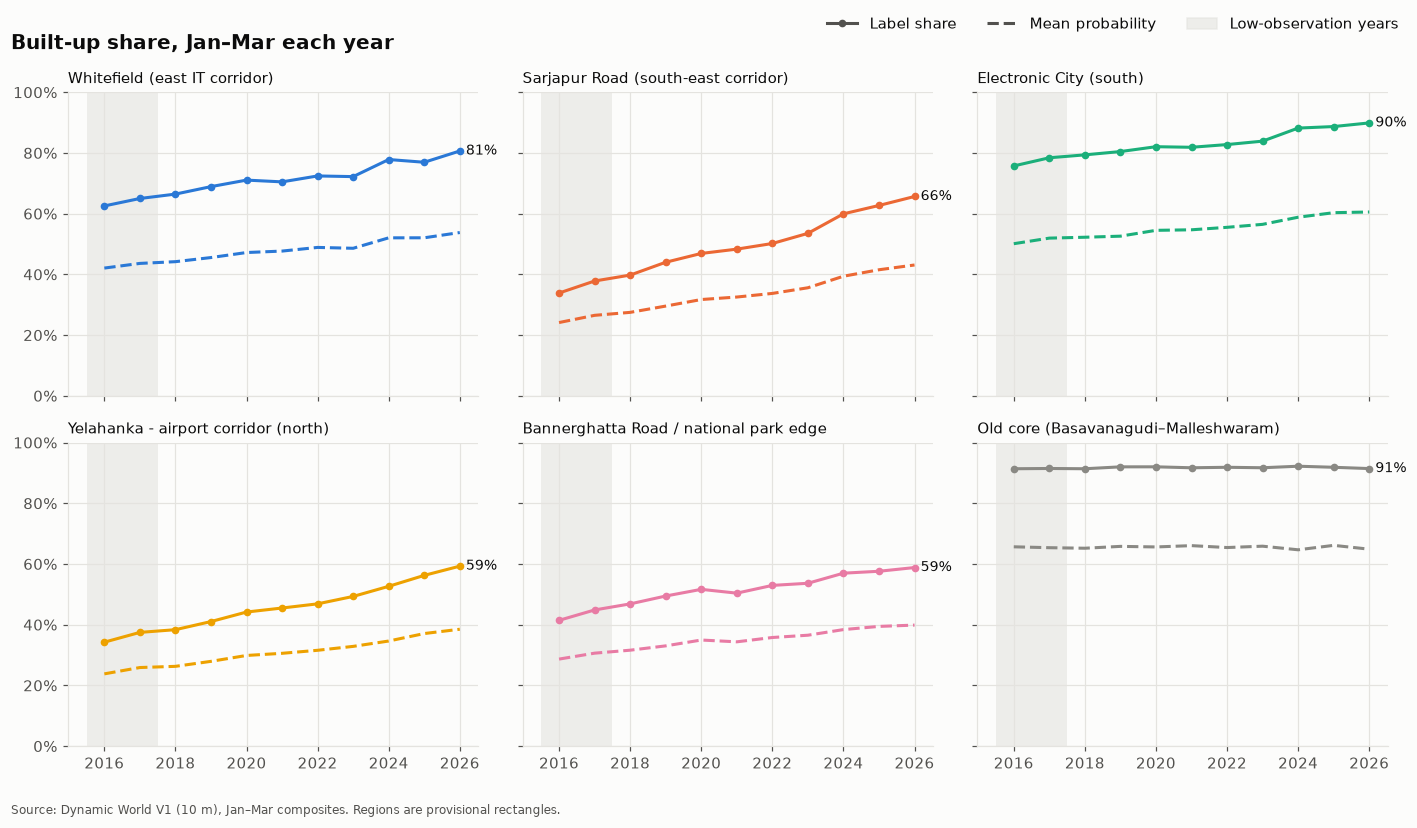

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True)
for ax, rid in zip(axes.flat, ORDER):
    d = wide[wide.region_id == rid].sort_values('year')
    c = COLORS[rid]
    ax.axvspan(min(LOW_OBS) - 0.5, max(LOW_OBS) + 0.5, color=GRID, alpha=0.6, lw=0)
    ax.plot(d.year, d.share_built, color=c, lw=2, marker='o', ms=4)
    ax.plot(d.year, d.soft_built, color=c, lw=2, ls='--')
    last = d.iloc[-1]
    ax.annotate(f'{last.share_built:.0%}', (last.year, last.share_built), xytext=(4, 0),
                textcoords='offset points', va='center', fontsize=9, color=INK)
    ax.set_title(LABELS[rid], loc='left', fontsize=10)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(pct)
    ax.set_xticks(range(2016, 2027, 2))
handles = [plt.Line2D([], [], color=INK_2, lw=2, marker='o', ms=4, label='Label share'),
           plt.Line2D([], [], color=INK_2, lw=2, ls='--', label='Mean probability'),
           plt.Rectangle((0, 0), 1, 1, color=GRID, alpha=0.6, label='Low-observation years')]
fig.legend(handles=handles, loc='upper right', ncol=3, frameon=False, bbox_to_anchor=(0.99, 1.02))
fig.suptitle('Built-up share, Jan–Mar each year', x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.tight_layout()
source_note(fig, 'Source: Dynamic World V1 (10 m), Jan–Mar composites. Regions are provisional rectangles.')
fig.savefig(OUT / 'built_share_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Built-up share, 2018 → 2026

Both endpoints are well-observed years (2016–17 excluded). Label share shown;
the mean-probability version is in the table below the chart.

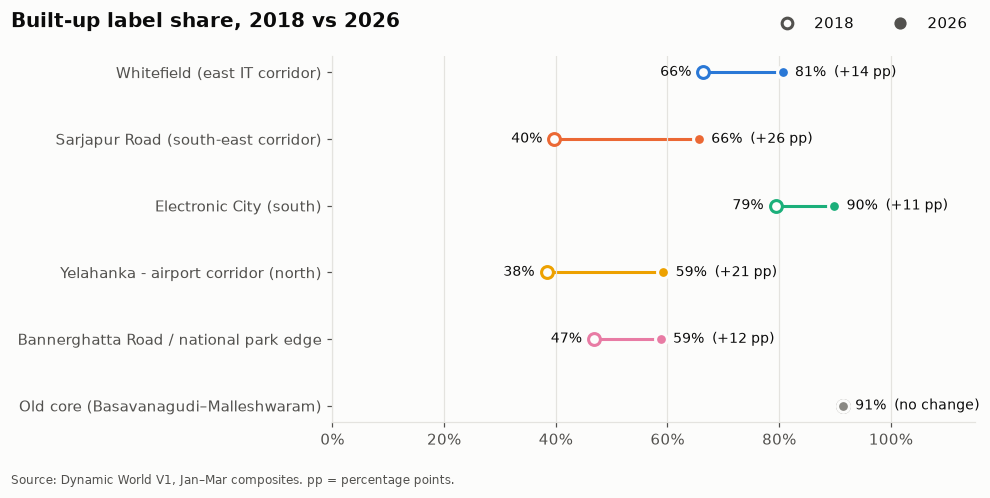

,label_2018,label_2026,prob_2018,prob_2026,label_change_pp,prob_change_pp
region_id,,,,,,
whitefield,0.664,0.806,0.442,0.538,14.202,9.599
sarjapur_road,0.398,0.657,0.275,0.431,25.892,15.606
electronic_city,0.794,0.899,0.522,0.605,10.523,8.315
north_airport_corridor,0.384,0.593,0.263,0.385,20.928,12.223
bannerghatta_edge,0.469,0.588,0.316,0.399,11.972,8.268
old_core,0.914,0.914,0.652,0.649,0.060,-0.314


In [4]:
ends = wide[wide.year.isin([2018, 2026])].pivot(index='region_id', columns='year',
                                                values=['share_built', 'soft_built'])
fig, ax = plt.subplots(figsize=(9, 4.2))
for i, rid in enumerate(reversed(ORDER)):
    a, b = ends.loc[rid, ('share_built', 2018)], ends.loc[rid, ('share_built', 2026)]
    c = COLORS[rid]
    ax.plot([a, b], [i, i], color=c, lw=2, zorder=1)
    ax.scatter([a], [i], s=60, facecolor=SURFACE, edgecolor=c, linewidth=2, zorder=2)
    ax.scatter([b], [i], s=60, color=c, edgecolor=SURFACE, linewidth=2, zorder=3)
    change_pp = (b - a) * 100
    if abs(change_pp) < 0.5:
        ax.annotate(f'{b:.0%}  (no change)', (max(a, b), i), xytext=(8, 0), textcoords='offset points',
                    va='center', fontsize=9)
    else:
        ax.annotate(f'{a:.0%}', (a, i), xytext=(-8, 0), textcoords='offset points', ha='right', va='center', fontsize=9)
        ax.annotate(f'{b:.0%}  ({change_pp:+.0f} pp)', (b, i), xytext=(8, 0), textcoords='offset points',
                    va='center', fontsize=9)
ax.set_yticks(range(len(ORDER)), [LABELS[r] for r in reversed(ORDER)])
ax.set_xlim(0, 1.15)
ax.xaxis.set_major_formatter(pct)
ax.grid(axis='y', visible=False)
handles = [plt.Line2D([], [], ls='', marker='o', ms=7, mfc=SURFACE, mec=INK_2, mew=2, label='2018'),
           plt.Line2D([], [], ls='', marker='o', ms=7, color=INK_2, label='2026')]
fig.legend(handles=handles, loc='upper right', ncol=2, frameon=False, bbox_to_anchor=(0.99, 1.0))
fig.suptitle('Built-up label share, 2018 vs 2026', x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.tight_layout()
source_note(fig, 'Source: Dynamic World V1, Jan–Mar composites. pp = percentage points.')
fig.savefig(OUT / 'built_share_2018_2026.png', dpi=150, bbox_inches='tight')
plt.show()

table = pd.DataFrame({
    'label_2018': ends[('share_built', 2018)], 'label_2026': ends[('share_built', 2026)],
    'prob_2018': ends[('soft_built', 2018)], 'prob_2026': ends[('soft_built', 2026)]}).loc[ORDER]
table['label_change_pp'] = (table.label_2026 - table.label_2018) * 100
table['prob_change_pp'] = (table.prob_2026 - table.prob_2018) * 100
table.round(3)

## 3. What land was converted (2018–19 → 2025–26)

Transitions between grouped classes, as a share of each region's area. A pixel counts only
if its class was the same in both start years and the same in both end years
(the persistence rule). **The old core is the noise reference**: it barely changed in
reality, so its values approximate classification noise.

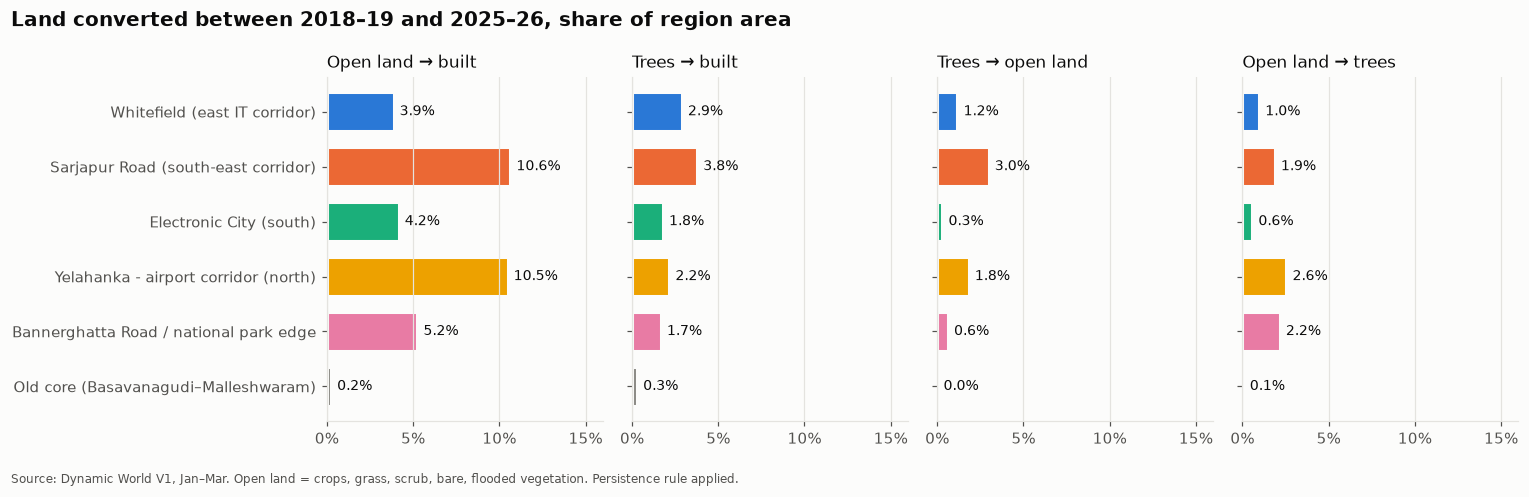

,area_km2,observed_ha,stable_ha,unstable_share
region_id,,,,
whitefield,36.146,3601.042,2936.711,0.184
sarjapur_road,79.548,7924.035,5777.995,0.271
electronic_city,36.165,3602.034,3205.097,0.110
north_airport_corridor,144.487,14394.505,10848.751,0.246
bannerghatta_edge,75.952,7566.189,6189.158,0.182
old_core,38.556,3840.791,3740.008,0.026


In [5]:
trans = pd.read_csv(OUT / 'transitions.csv')
summary = pd.read_csv(OUT / 'transitions_summary.csv').set_index('region_id')
trans['share_of_region'] = trans.apply(
    lambda r: r.area_ha / (summary.loc[r.region_id, 'area_km2'] * 100), axis=1)
KINDS = [('open_land', 'built', 'Open land → built'), ('trees', 'built', 'Trees → built'),
         ('trees', 'open_land', 'Trees → open land'), ('open_land', 'trees', 'Open land → trees')]

fig, axes = plt.subplots(1, 4, figsize=(14, 4.2), sharey=True)
for ax, (src, dst, title) in zip(axes, KINDS):
    sub = trans[(trans.from_class == src) & (trans.to_class == dst)].set_index('region_id')
    vals = [sub.share_of_region.get(r, 0.0) for r in reversed(ORDER)]
    y = range(len(ORDER))
    ax.barh(list(y), vals, color=[COLORS[r] for r in reversed(ORDER)], height=0.7,
            edgecolor=SURFACE, linewidth=2)
    for yi, v in zip(y, vals):
        ax.annotate(f'{v:.1%}', (v, yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9)
    ax.set_title(title, loc='left', fontsize=11)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
    ax.set_xlim(0, 0.16)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(range(len(ORDER)), [LABELS[r] for r in reversed(ORDER)])
fig.suptitle('Land converted between 2018–19 and 2025–26, share of region area',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.tight_layout()
source_note(fig, 'Source: Dynamic World V1, Jan–Mar. Open land = crops, grass, scrub, bare, flooded vegetation. '
                 'Persistence rule applied.')
fig.savefig(OUT / 'transitions.png', dpi=150, bbox_inches='tight')
plt.show()

summary.loc[ORDER, ['area_km2', 'observed_ha', 'stable_ha', 'unstable_share']].round(3)

## 4. Vegetation (NDVI), dry season

Median NDVI of cloud-masked Sentinel-2 scenes (top-of-atmosphere). Year-to-year swings are
shared across regions — that pattern points to **rainfall**, not land change. Not interpretable
as a land-use signal until rainfall is controlled for.

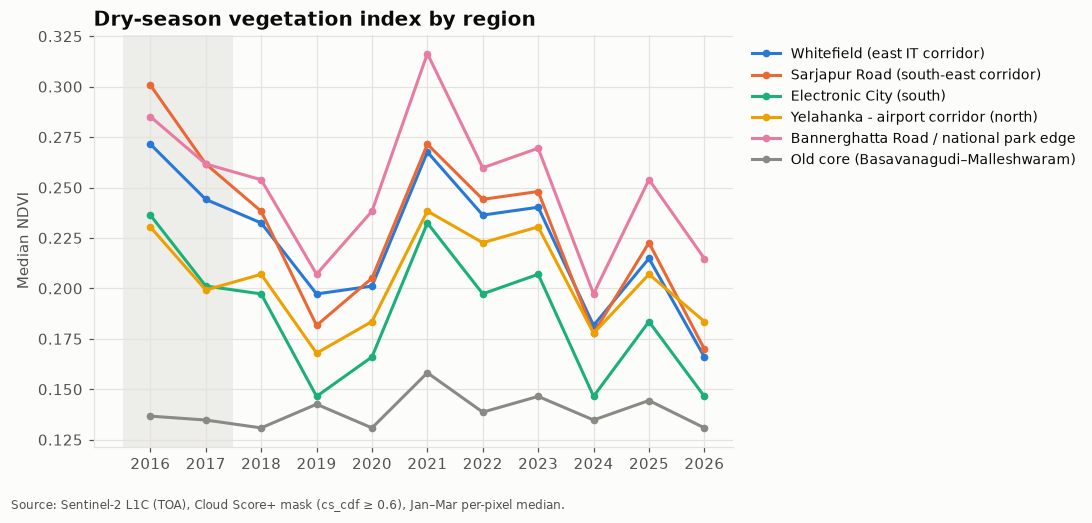

region_id,whitefield,sarjapur_road,electronic_city,north_airport_corridor,bannerghatta_edge,old_core
year,,,,,,
2016,0.271,0.301,0.236,0.230,0.285,0.137
2017,0.244,0.262,0.201,0.199,0.262,0.135
2018,0.232,0.238,0.197,0.207,0.254,0.131
2019,0.197,0.182,0.146,0.168,0.207,0.143
2020,0.201,0.205,0.166,0.184,0.238,0.131
2021,0.268,0.271,0.232,0.238,0.316,0.158
2022,0.236,0.244,0.197,0.223,0.260,0.139
2023,0.240,0.248,0.207,0.230,0.269,0.146
2024,0.182,0.178,0.146,0.178,0.197,0.135


In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(min(LOW_OBS) - 0.5, max(LOW_OBS) + 0.5, color=GRID, alpha=0.6, lw=0)
for rid in ORDER:
    d = wide[wide.region_id == rid].sort_values('year')
    ax.plot(d.year, d.ndvi_median, color=COLORS[rid], lw=2, marker='o', ms=4, label=LABELS[rid])
ax.set_ylabel('Median NDVI')
ax.set_xticks(range(2016, 2027))
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
ax.set_title('Dry-season vegetation index by region', loc='left', fontsize=13, fontweight='bold')
fig.tight_layout()
source_note(fig, 'Source: Sentinel-2 L1C (TOA), Cloud Score+ mask (cs_cdf ≥ 0.6), Jan–Mar per-pixel median.')
fig.savefig(OUT / 'ndvi.png', dpi=150, bbox_inches='tight')
plt.show()

wide.pivot(index='year', columns='region_id', values='ndvi_median')[ORDER].round(3)

## Observations (provisional — see `findings.md` for confidence levels)

Written after looking at the charts above; every claim is about the **provisional
rectangles**, not official localities.

- **The reference behaves.** The old core's built-up share is flat (~91–92% label share)
  and only ~3% of its area is unstable — the method is not manufacturing growth.
- **All five growth regions rise steadily**, in both measures, from 2018 to 2026
  (label share +11 to +26 pp; Sarjapur Road and the north airport corridor fastest).
- **Conversion is mostly open land → built** (3.9–10.6% of region area vs 0.2% in the core).
  **Trees → built** is smaller but well above the core's noise level in every growth region
  (1.7–3.8% vs 0.3%).
- **Transitions understate change.** 11–27% of each growth region is unstable under the
  persistence rule (e.g. land under construction), so the stable transitions are a lower bound —
  Sarjapur Road's +26 pp label-share gain vs 14% stable conversion to built.
- **NDVI moves together across all regions** (dips in 2019 and 2024, peak in 2021), pointing to
  rainfall rather than land change; not usable as a land-use signal until rainfall is controlled for.

What would change these conclusions: official boundaries shifting the rectangles, building
footprint data disagreeing with Dynamic World, or a different seasonal window.